# Đánh giá VLM trên POPE: Accuracy, Precision, Recall, F1 và phân tích Hallucination

**Đề tài:** Xây dựng pipeline dữ liệu đa phương thức phục vụ kiểm chứng thông tin và giảm ảo giác trong hệ thống trí tuệ nhân tạo.

**Mục tiêu notebook:** so sánh `prediction` của `Qwen3-VL-4B-Instruct` (kết quả từ `vlm_inference.ipynb`) với `answer` ground truth của POPE, tính chỉ số, vẽ biểu đồ và phân tích các trường hợp sai.

Notebook **độc lập**: chỉ cần `vlm_predictions.csv` (tuỳ chọn thêm `inference_summary.json`) và dataset POPE để lấy ground truth. **Không** tải lại model.

## Hướng dẫn trên Kaggle
1. Thêm output của notebook inference làm **Input** (Add Input → Notebook Output) hoặc upload `vlm_predictions.csv` (+ `inference_summary.json`) thành một Kaggle Dataset rồi thêm vào notebook.
2. Cần **Internet: On** để tải ground truth từ Hugging Face; nếu không có Internet, thêm file Parquet của POPE làm Input và đặt `GT_SOURCE = "local_parquet"`.
3. Không cần GPU cho notebook này.
4. Chạy lần lượt các cell từ trên xuống.

## Quy ước
- **Positive label = `Yes`** (đối tượng được hỏi *có* xuất hiện trong ảnh), negative = `No`.
- Mẫu inference lỗi (`status = error`) hoặc `Invalid` **không** được đưa vào metrics chính; số lượng của chúng được báo cáo riêng.
- Ghép dữ liệu bằng khoá định danh duy nhất (ưu tiên `id`), **không** ghép theo vị trí dòng.

---
# PHẦN 1: CẤU HÌNH MÔI TRƯỜNG

In [1]:
# 1.1 Cài thư viện còn thiếu (Kaggle thường đã có sẵn nên cell này thường không cài gì)
import sys
import subprocess
from importlib.metadata import version as pkg_version, PackageNotFoundError

required = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
            "scikit-learn": "scikit-learn", "pyarrow": "pyarrow", "datasets": "datasets",
            "huggingface_hub": "huggingface_hub", "Pillow": "Pillow", "tqdm": "tqdm"}
missing = []
for pip_name in required:
    try:
        print(f"{pip_name:<16}: {pkg_version(pip_name)}")
    except PackageNotFoundError:
        missing.append(pip_name)
if missing:
    print("Cài các gói còn thiếu:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)
else:
    print("Đã đủ thư viện, không cần cài thêm.")

pandas          : 2.3.3
numpy           : 2.1.3
matplotlib      : 3.10.0
seaborn         : 0.13.2
scikit-learn    : 1.6.1
pyarrow         : 23.0.1
datasets        : 4.8.5
huggingface_hub : 1.33.0
Pillow          : 13.0.0
tqdm            : 4.67.3
Đã đủ thư viện, không cần cài thêm.


In [2]:
# 1.2 Import thư viện và khai báo cấu hình
import io
import re
import json
import socket
import textwrap
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- Đầu vào ----------------
PREDICTIONS_CSV = None           # None = tự tìm vlm_predictions.csv; hoặc đặt đường dẫn, vd "/kaggle/input/<ten>/vlm_predictions.csv"
GT_SOURCE = "hub_parquet"        # "hub_parquet": tải file Parquet từ Hugging Face | "local_parquet": file Parquet có sẵn
DATASET_NAME = "lmms-lab-encoder/POPE"
LOCAL_PARQUET_DIR = None         # Ví dụ: "/kaggle/input/pope-parquet" khi GT_SOURCE = "local_parquet"
GT_SPLIT = "auto"                # "auto": lấy split từ inference_summary.json (nếu có) | tên split | "all"

# ---------------- Tuỳ chọn đánh giá ----------------
STRICT_QUESTION_CHECK = True     # True: dừng nếu câu hỏi ở prediction và ground truth không khớp sau khi ghép
NUM_ERROR_SHOW = 8               # Số mẫu sai hiển thị kèm ảnh cho mỗi loại lỗi
SEED = 42

# ---------------- Hằng số nhãn ----------------
LABELS = ["No", "Yes"]           # Thứ tự nhãn cố định
POSITIVE_LABEL = "Yes"

# ---------------- Đường dẫn output ----------------
IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path.cwd()
OUTPUT_DIR = WORK_DIR / "evaluation_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Thư mục output:", OUTPUT_DIR.resolve())

Thư mục output: /kaggle/working/evaluation_output


---
# PHẦN 2: ĐỌC KẾT QUẢ INFERENCE
Tìm và đọc `vlm_predictions.csv`. Các cột `id`, `question_id` được đọc dạng chuỗi để không mất số 0 đầu hoặc bị đổi sang số thực.

In [3]:
# 2.1 Tìm và kiểm tra file kết quả inference
def find_prediction_file(explicit_path=None):
    # Tìm vlm_predictions.csv: dùng đường dẫn chỉ định hoặc quét Kaggle Input / working / thư mục hiện tại
    if explicit_path:
        path = Path(explicit_path)
        if not path.is_file():
            raise FileNotFoundError(f"Không tìm thấy file: {path}")
        return path
    candidates = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd()]:
        if root.exists():
            candidates.extend(root.rglob("vlm_predictions.csv"))
    candidates = sorted({p.resolve() for p in candidates}, key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(
            "Không tìm thấy vlm_predictions.csv. Hãy thêm output của notebook inference làm Input "
            "(Add Input -> Notebook Output) hoặc đặt PREDICTIONS_CSV ở cell 1.2.")
    if len(candidates) > 1:
        print("Tìm thấy nhiều file, dùng file mới nhất. Danh sách:")
        for candidate in candidates:
            print("  -", candidate)
    return candidates[0]


PREDICTIONS_PATH = find_prediction_file(PREDICTIONS_CSV)
print("Đọc kết quả inference từ:", PREDICTIONS_PATH)

# Đọc summary đi kèm (nếu có) để lấy dataset/split đã dùng khi inference
inference_summary = {}
summary_candidate = PREDICTIONS_PATH.parent / "inference_summary.json"
if summary_candidate.is_file():
    inference_summary = json.loads(summary_candidate.read_text(encoding="utf-8"))
    print("Đã đọc inference_summary.json | model:", inference_summary.get("model_name"),
          "| split:", inference_summary.get("dataset_split"))
else:
    print("Không có inference_summary.json cạnh file CSV (không bắt buộc).")

Đọc kết quả inference từ: /kaggle/input/datasets/phhtt1/output/vlm_predictions.csv
Đã đọc inference_summary.json | model: Qwen/Qwen3-VL-4B-Instruct | split: test


In [4]:
# 2.2 Đọc CSV và kiểm tra cấu trúc
pred_raw = pd.read_csv(PREDICTIONS_PATH, dtype={"id": str, "question_id": str},
                       keep_default_na=False, na_values=[""], encoding="utf-8")

REQUIRED_PRED_COLUMNS = ["id", "prediction", "status"]
missing_cols = [c for c in REQUIRED_PRED_COLUMNS if c not in pred_raw.columns]
if missing_cols:
    raise ValueError(f"File prediction thiếu cột bắt buộc: {missing_cols}. Cột hiện có: {list(pred_raw.columns)}")

print("Số dòng:", len(pred_raw))
print("Các cột:", list(pred_raw.columns))
print("\nKiểu dữ liệu:")
print(pred_raw.dtypes)
print("\nSố giá trị null theo cột:")
print(pred_raw.isna().sum())

print("\nThống kê status:")
print(pred_raw["status"].value_counts(dropna=False))
print("\nThống kê prediction (Yes / No / Invalid / rỗng):")
print(pred_raw["prediction"].value_counts(dropna=False))

Số dòng: 9000
Các cột: ['id', 'question_id', 'question', 'prediction', 'image_source', 'category', 'status', 'error', 'raw_output', 'row_index', 'sample_key']

Kiểu dữ liệu:
id               object
question_id      object
question         object
prediction       object
image_source     object
category         object
status           object
error           float64
raw_output       object
row_index         int64
sample_key        int64
dtype: object

Số giá trị null theo cột:
id                 0
question_id        0
question           0
prediction         0
image_source       0
category           0
status             0
error           9000
raw_output         0
row_index          0
sample_key         0
dtype: int64

Thống kê status:
status
success    9000
Name: count, dtype: int64

Thống kê prediction (Yes / No / Invalid / rỗng):
prediction
No     5114
Yes    3886
Name: count, dtype: int64


## 2.3 Chuẩn hoá nhãn và lọc mẫu hợp lệ
Chỉ giữ mẫu có `status = success` **và** prediction chuẩn hoá được thành `Yes`/`No`. Nhãn không xác định **không** bị thay thế mà bị loại khỏi metrics và được liệt kê riêng.

In [5]:
# 2.3 Chuẩn hoá nhãn và xác định mẫu hợp lệ / không hợp lệ
LABEL_MAP = {"yes": "Yes", "no": "No"}


def normalize_label(value):
    # Chuẩn hoá giá trị nhãn về Yes/No; trả về None nếu không xác định (không tự suy diễn)
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    return LABEL_MAP.get(str(value).strip().lower())


pred_df = pred_raw.copy()
pred_df["prediction_norm"] = pred_df["prediction"].map(normalize_label)
pred_df["is_valid_prediction"] = (pred_df["status"] == "success") & pred_df["prediction_norm"].notna()

excluded_predictions = pred_df[~pred_df["is_valid_prediction"]].copy()
print(f"Mẫu hợp lệ cho metrics: {int(pred_df['is_valid_prediction'].sum())} / {len(pred_df)}")
print(f"Mẫu bị loại (error / Invalid / nhãn lạ): {len(excluded_predictions)}")
if len(excluded_predictions):
    print(excluded_predictions["status"].value_counts(dropna=False).to_string())
    show_cols = [c for c in ["id", "question", "prediction", "status", "error", "raw_output"] if c in excluded_predictions.columns]
    print(excluded_predictions[show_cols].head(10).to_string())

Mẫu hợp lệ cho metrics: 9000 / 9000
Mẫu bị loại (error / Invalid / nhãn lạ): 0


---
# PHẦN 3: ĐỌC GROUND TRUTH VÀ GHÉP DỮ LIỆU
Ground truth được đọc từ các file Parquet của POPE (cùng split với lúc inference). Các file Parquet được gộp thành một tập; cột ảnh chỉ được dùng ở Phần 6 để hiển thị mẫu sai (memory-mapped, không nạp toàn bộ vào RAM).

In [6]:
# 3.1 Hàm tìm file Parquet theo split (độc lập với notebook inference)
KNOWN_SPLITS = {"train", "test", "validation", "val", "dev"}


def infer_split_from_path(file_path):
    # Suy ra split từ đường dẫn file Parquet (vd data/test-00000-of-00004.parquet -> test)
    path = Path(file_path)
    match = re.match(r"^([A-Za-z_]+)-\d+-of-\d+", path.name)
    if match:
        return match.group(1).lower()
    for part in reversed(path.parts[:-1]):
        if part.lower() in KNOWN_SPLITS:
            return part.lower()
    stem_without_digits = re.sub(r"[-_]?\d+$", "", path.stem)
    return (stem_without_digits or path.stem).lower()


def group_files_by_split(file_paths):
    # Nhóm file theo split, sắp xếp tên để thứ tự ổn định
    groups = {}
    for file_path in sorted(str(p) for p in file_paths):
        groups.setdefault(infer_split_from_path(file_path), []).append(file_path)
    return groups


def list_hub_parquet_files(repo_id):
    # Liệt kê file .parquet của dataset trên Hugging Face
    from huggingface_hub import HfApi
    files = HfApi().list_repo_files(repo_id, repo_type="dataset")
    return group_files_by_split([f for f in files if f.lower().endswith(".parquet")])


def list_local_parquet_files(local_dir):
    # Liệt kê file .parquet trong thư mục local (vd Kaggle Input)
    base = Path(local_dir)
    if not base.exists():
        raise FileNotFoundError(f"Không tìm thấy thư mục: {base}")
    relative_to_abs = {str(p.relative_to(base)): str(p) for p in base.rglob("*.parquet")}
    groups = group_files_by_split(relative_to_abs.keys())
    return {split: [relative_to_abs[rel] for rel in rels] for split, rels in groups.items()}


def resolve_split(available_groups, requested):
    # Chọn split; báo lỗi rõ ràng nếu không xác định được
    if not available_groups:
        raise ValueError("Không tìm thấy file Parquet nào.")
    if requested == "all":
        return "all"
    if requested not in (None, "auto"):
        if requested not in available_groups:
            raise ValueError(f"Split '{requested}' không tồn tại. Các split có sẵn: {sorted(available_groups)}")
        return requested
    if len(available_groups) == 1:
        return next(iter(available_groups))
    if "test" in available_groups:
        return "test"
    raise ValueError(f"Có nhiều split {sorted(available_groups)}; hãy đặt GT_SPLIT cụ thể ở cell 1.2.")

In [7]:
# 3.2 Tải ground truth: gộp mọi file Parquet của split và tạo bảng metadata (không chứa ảnh)
from datasets import load_dataset, Image as HFImage

# Ưu tiên split đã dùng khi inference (từ summary) nếu GT_SPLIT = "auto"
requested_split = GT_SPLIT
if GT_SPLIT == "auto" and inference_summary.get("dataset_split"):
    requested_split = inference_summary["dataset_split"]
    print("Dùng split từ inference_summary.json:", requested_split)

try:
    if GT_SOURCE == "hub_parquet":
        from huggingface_hub import hf_hub_download
        groups = list_hub_parquet_files(DATASET_NAME)
    elif GT_SOURCE == "local_parquet":
        if not LOCAL_PARQUET_DIR:
            raise ValueError("Hãy đặt LOCAL_PARQUET_DIR khi GT_SOURCE = 'local_parquet'.")
        groups = list_local_parquet_files(LOCAL_PARQUET_DIR)
    else:
        raise ValueError(f"GT_SOURCE không hợp lệ: {GT_SOURCE}")

    print("Các split / số file Parquet:", {k: len(v) for k, v in groups.items()})
    GT_SPLIT_NAME = resolve_split(groups, requested_split)
    selected_files = sorted(f for files in groups.values() for f in files) if GT_SPLIT_NAME == "all" else groups[GT_SPLIT_NAME]
    if GT_SOURCE == "hub_parquet":
        local_files = [hf_hub_download(DATASET_NAME, filename=f, repo_type="dataset") for f in selected_files]
    else:
        local_files = selected_files
    # Gộp tất cả file Parquet thành một Dataset duy nhất
    gt_ds = load_dataset("parquet", data_files=[str(p) for p in local_files], split="train")
except Exception as exc:
    raise RuntimeError(f"Không tải được ground truth: {exc}\n"
                       "Kiểm tra Internet (Settings -> Internet: On) hoặc dùng GT_SOURCE = 'local_parquet'.") from exc

if "image" in gt_ds.column_names and isinstance(gt_ds.features["image"], HFImage):
    gt_ds = gt_ds.cast_column("image", HFImage(decode=False))  # Giữ dạng dict {bytes, path}

wanted = [c for c in ["id", "question_id", "question", "answer", "category", "image_source"] if c in gt_ds.column_names]
gt_df = gt_ds.select_columns(wanted).to_pandas()
gt_df["gt_row_index"] = np.arange(len(gt_df))  # Vị trí dòng trong gt_ds, chỉ dùng để lấy ảnh ở Phần 6

print("\nGround truth split:", GT_SPLIT_NAME, "| số mẫu:", len(gt_df))
print("Các cột:", list(gt_df.columns))
print("\nSố giá trị null:")
print(gt_df.isna().sum())
if "answer" not in gt_df.columns:
    raise ValueError("Dataset ground truth không có cột 'answer'.")
print("\nGiá trị cột answer (thô):")
print(gt_df["answer"].value_counts(dropna=False))

Dùng split từ inference_summary.json: test
Các split / số file Parquet: {'adversarial': 1, 'popular': 1, 'random': 1, 'test': 3}


data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]


Ground truth split: test | số mẫu: 9000
Các cột: ['id', 'question_id', 'question', 'answer', 'category', 'image_source', 'gt_row_index']

Số giá trị null:
id              0
question_id     0
question        0
answer          0
category        0
image_source    0
gt_row_index    0
dtype: int64

Giá trị cột answer (thô):
answer
yes    4500
no     4500
Name: count, dtype: int64


## 3.3 Chọn khoá ghép
Thử lần lượt `id`, `question_id`, `id + question_id`, `id + question_id + question`; khoá hợp lệ phải tồn tại ở cả hai phía và **duy nhất ở cả hai phía**. Nếu không có khoá nào thoả, notebook dừng (không ghép theo vị trí dòng).

In [8]:
# 3.3 Chọn khoá ghép duy nhất giữa prediction và ground truth
def normalize_key_column(series):
    # Chuẩn hoá cột khoá về chuỗi đã strip để so khớp ổn định giữa CSV và Parquet
    return series.astype(str).str.strip()


KEY_CANDIDATES = [["id"], ["question_id"], ["id", "question_id"], ["id", "question_id", "question"]]


def choose_merge_key(pred, gt):
    # Trả về danh sách cột khoá đầu tiên hợp lệ và báo cáo lý do loại các ứng viên khác
    for key_cols in KEY_CANDIDATES:
        if not all(c in pred.columns and c in gt.columns for c in key_cols):
            print(f"  {key_cols}: bỏ qua (thiếu cột ở một trong hai phía)")
            continue
        pred_keys = pred[key_cols].apply(normalize_key_column)
        gt_keys = gt[key_cols].apply(normalize_key_column)
        pred_dups = int(pred_keys.duplicated().sum())
        gt_dups = int(gt_keys.duplicated().sum())
        if pred_dups or gt_dups:
            print(f"  {key_cols}: không duy nhất (trùng ở prediction = {pred_dups}, ở ground truth = {gt_dups})")
            continue
        print(f"  {key_cols}: hợp lệ (duy nhất ở cả hai phía)")
        return key_cols
    raise ValueError("Không có khoá ghép nào duy nhất ở cả prediction và ground truth. "
                     "Không ghép theo vị trí dòng; hãy kiểm tra lại dữ liệu đầu vào.")


print("Kiểm tra các ứng viên khoá ghép:")
MERGE_KEY = choose_merge_key(pred_df, gt_df)
print("\n=> Khoá ghép được chọn:", MERGE_KEY)

Kiểm tra các ứng viên khoá ghép:
  ['id']: hợp lệ (duy nhất ở cả hai phía)

=> Khoá ghép được chọn: ['id']


In [9]:
# 3.4 Ghép prediction với ground truth bằng khoá đã chọn và kiểm tra các mẫu không ghép được
pred_side = pred_df.copy()
gt_side = gt_df.copy()
for key_col in MERGE_KEY:
    pred_side[key_col] = normalize_key_column(pred_side[key_col])
    gt_side[key_col] = normalize_key_column(gt_side[key_col])

gt_keep = MERGE_KEY + [c for c in ["question", "answer", "category", "image_source", "gt_row_index"]
                       if c in gt_side.columns and c not in MERGE_KEY]
gt_side = gt_side[gt_keep].rename(columns={c: f"{c}_gt" for c in gt_keep if c not in MERGE_KEY})

merged_all = pred_side.merge(gt_side, on=MERGE_KEY, how="outer", indicator=True, validate="one_to_one")

n_pred, n_gt = len(pred_side), len(gt_side)
n_both = int((merged_all["_merge"] == "both").sum())
n_pred_only = int((merged_all["_merge"] == "left_only").sum())
n_gt_only = int((merged_all["_merge"] == "right_only").sum())

print(f"Số mẫu prediction trước merge : {n_pred}")
print(f"Số mẫu ground truth trước merge: {n_gt}")
print(f"Ghép được (both)               : {n_both}")
print(f"Chỉ có ở prediction (không có ground truth): {n_pred_only}")
print(f"Chỉ có ở ground truth (chưa được inference) : {n_gt_only}  -> bình thường nếu inference chỉ chạy một phần dataset")
if n_pred_only:
    print("\nCẢNH BÁO: có mẫu prediction không khớp ground truth (có thể sai split/dataset). Ví dụ:")
    print(merged_all[merged_all["_merge"] == "left_only"][MERGE_KEY].head(10).to_string())
if n_both == 0:
    raise ValueError("Không ghép được mẫu nào. Kiểm tra DATASET_NAME / GT_SPLIT và khoá ghép.")

merged = merged_all[merged_all["_merge"] == "both"].copy()
print("\nKiểm tra trùng lặp sau merge - số khoá trùng:", int(merged[MERGE_KEY].duplicated().sum()))

# Kiểm tra tính nhất quán: câu hỏi ở prediction phải trùng câu hỏi ở ground truth
if "question" in merged.columns and "question_gt" in merged.columns:
    question_mismatch = merged["question"].astype(str).str.strip() != merged["question_gt"].astype(str).str.strip()
    n_mismatch = int(question_mismatch.sum())
    print(f"Số mẫu có câu hỏi không khớp giữa prediction và ground truth: {n_mismatch}")
    if n_mismatch:
        print(merged.loc[question_mismatch, MERGE_KEY + ["question", "question_gt"]].head(10).to_string())
        if STRICT_QUESTION_CHECK:
            raise ValueError("Câu hỏi không khớp: khoá ghép có thể sai hoặc dữ liệu thuộc split khác. "
                             "Đặt STRICT_QUESTION_CHECK = False nếu bạn chắc chắn đây chỉ là khác biệt định dạng.")
if "category" in merged.columns and "category_gt" in merged.columns:
    category_mismatch = (merged["category"].astype(str) != merged["category_gt"].astype(str)).sum()
    print("Số mẫu có category không khớp (chỉ cảnh báo):", int(category_mismatch))

Số mẫu prediction trước merge : 9000
Số mẫu ground truth trước merge: 9000
Ghép được (both)               : 9000
Chỉ có ở prediction (không có ground truth): 0
Chỉ có ở ground truth (chưa được inference) : 0  -> bình thường nếu inference chỉ chạy một phần dataset

Kiểm tra trùng lặp sau merge - số khoá trùng: 0
Số mẫu có câu hỏi không khớp giữa prediction và ground truth: 0
Số mẫu có category không khớp (chỉ cảnh báo): 0


## 3.5 Chuẩn hoá nhãn ground truth và tạo bảng đánh giá
Cấu trúc: `id | question | category | answer | prediction` (kèm cột phụ phục vụ truy vết). Nhãn ground truth không xác định bị loại và được báo cáo, không bị thay thế.

In [10]:
# 3.5 Tạo DataFrame đánh giá cuối cùng
merged["answer_norm"] = merged["answer_gt"].map(normalize_label)

invalid_gt_mask = merged["answer_norm"].isna()
print("Số mẫu có nhãn ground truth không hợp lệ:", int(invalid_gt_mask.sum()))
if invalid_gt_mask.any():
    print(merged.loc[invalid_gt_mask, MERGE_KEY + ["answer_gt"]].head(10).to_string())

eligible_mask = merged["is_valid_prediction"].astype(bool) & ~invalid_gt_mask
excluded_after_merge = merged[~eligible_mask]
print(f"\nMẫu ghép được nhưng bị loại khỏi metrics (prediction lỗi/Invalid hoặc GT không hợp lệ): {len(excluded_after_merge)}")

eval_source = merged[eligible_mask]
if "category_gt" in eval_source.columns:
    category_values = eval_source["category_gt"].values
elif "category" in eval_source.columns:
    category_values = eval_source["category"].values
else:
    category_values = ["(missing)"] * len(eval_source)
eval_df = pd.DataFrame({
    "id": eval_source["id"].values,
    "question": (eval_source["question"] if "question" in eval_source.columns else eval_source["question_gt"]).values,
    "category": category_values,
    "answer": eval_source["answer_norm"].values,
    "prediction": eval_source["prediction_norm"].values,
})
if "question_id" in eval_source.columns:
    eval_df["question_id"] = eval_source["question_id"].values
if "image_source_gt" in eval_source.columns:
    eval_df["image_source"] = eval_source["image_source_gt"].values
eval_df["gt_row_index"] = eval_source["gt_row_index_gt"].astype(int).values
eval_df = eval_df.reset_index(drop=True)

# Kiểm tra nhãn cuối cùng chỉ chứa Yes/No
assert set(eval_df["answer"].unique()) <= set(LABELS), "Nhãn answer chứa giá trị ngoài Yes/No"
assert set(eval_df["prediction"].unique()) <= set(LABELS), "Nhãn prediction chứa giá trị ngoài Yes/No"

coverage = {
    "prediction_rows": n_pred, "ground_truth_rows": n_gt, "matched": n_both,
    "prediction_only": n_pred_only, "ground_truth_only": n_gt_only,
    "excluded_from_metrics": len(excluded_after_merge), "evaluated": len(eval_df),
}
print("\nBảng đánh giá:", eval_df.shape)
try:
    display(eval_df.head(10))
except NameError:
    print(eval_df.head(10).to_string())

Số mẫu có nhãn ground truth không hợp lệ: 0

Mẫu ghép được nhưng bị loại khỏi metrics (prediction lỗi/Invalid hoặc GT không hợp lệ): 0

Bảng đánh giá: (9000, 8)


,id,question,category,answer,prediction,question_id,image_source,gt_row_index
0,0,Is there a snowboard in the image?,adversarial,Yes,Yes,1,COCO_val2014_000000310196,0
1,1,Is there a backpack in the image?,adversarial,No,No,2,COCO_val2014_000000310196,1
2,10,Is there an umbrella in the imange?,adversarial,Yes,Yes,11,COCO_val2014_000000210789,10
3,100,Is there a handbag in the image?,adversarial,Yes,Yes,101,COCO_val2014_000000482476,100
4,1000,Is there a fork in the image?,adversarial,Yes,Yes,1001,COCO_val2014_000000468934,1000
5,1001,Is there a cup in the image?,adversarial,No,No,1002,COCO_val2014_000000468934,1001
6,1002,Is there a sink in the image?,adversarial,Yes,Yes,1003,COCO_val2014_000000189694,1002
7,1003,Is there a toilet in the image?,adversarial,No,No,1004,COCO_val2014_000000189694,1003
8,1004,Is there a person in the image?,adversarial,Yes,Yes,1005,COCO_val2014_000000189694,1004
9,1005,Is there a car in the image?,adversarial,No,No,1006,COCO_val2014_000000189694,1005


---
# PHẦN 4: TÍNH CÁC CHỈ SỐ ĐÁNH GIÁ

Positive label = **Yes** (đối tượng có trong ảnh). Với mỗi mẫu:

| Ký hiệu | Ground truth | Prediction | Ý nghĩa |
|---|---|---|---|
| **TP** (True Positive) | Yes | Yes | Đối tượng có trong ảnh và model xác nhận đúng |
| **TN** (True Negative) | No | No | Đối tượng không có và model phủ nhận đúng |
| **FP** (False Positive) | No | Yes | Model khẳng định đối tượng **không có** trong ảnh → biểu hiện của *object hallucination* |
| **FN** (False Negative) | Yes | No | Model bỏ sót đối tượng **có** trong ảnh |

Công thức: `Accuracy = (TP+TN)/(TP+TN+FP+FN)`, `Precision = TP/(TP+FP)`, `Recall = TP/(TP+FN)`, `F1 = 2·P·R/(P+R)`. Bổ sung hai chỉ số quen dùng với POPE: **Yes-ratio** (tỷ lệ model trả lời Yes; lệch cao cho thấy xu hướng "ảo giác khẳng định") và **FPR** = FP/(FP+TN).

In [11]:
# 4.1 Hàm tính chỉ số nhất quán (positive label = Yes) bằng scikit-learn
def compute_binary_metrics(y_true, y_pred):
    # Trả về dict chỉ số và số TP/TN/FP/FN
    y_true = pd.Series(list(y_true))
    y_pred = pd.Series(list(y_pred))
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)  # Hàng = thực tế, cột = dự đoán, thứ tự [No, Yes]
    tn, fp, fn, tp = (int(v) for v in cm.ravel())
    return {
        "samples": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, pos_label=POSITIVE_LABEL, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, pos_label=POSITIVE_LABEL, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, pos_label=POSITIVE_LABEL, zero_division=0)),
        "yes_ratio": float((y_pred == POSITIVE_LABEL).mean()),
        "false_positive_rate": float(fp / (fp + tn)) if (fp + tn) else 0.0,
        "tp": tp, "tn": tn, "fp": fp, "fn": fn,
    }


if len(eval_df) == 0:
    raise ValueError("Không có mẫu hợp lệ để tính metrics.")

overall_metrics = compute_binary_metrics(eval_df["answer"], eval_df["prediction"])
cm_overall = confusion_matrix(eval_df["answer"], eval_df["prediction"], labels=LABELS)
report_text = classification_report(eval_df["answer"], eval_df["prediction"], labels=LABELS,
                                    target_names=LABELS, digits=4, zero_division=0)
report_dict = classification_report(eval_df["answer"], eval_df["prediction"], labels=LABELS,
                                    target_names=LABELS, digits=4, zero_division=0, output_dict=True)

print(f"Số mẫu đánh giá: {overall_metrics['samples']}  (positive label = '{POSITIVE_LABEL}')\n")
for name in ["accuracy", "precision", "recall", "f1", "yes_ratio", "false_positive_rate"]:
    print(f"{name:<22}: {overall_metrics[name]:.4f}")
print(f"\nTP={overall_metrics['tp']}  TN={overall_metrics['tn']}  FP={overall_metrics['fp']}  FN={overall_metrics['fn']}")
print("\nConfusion matrix (hàng = thực tế, cột = dự đoán, thứ tự [No, Yes]):")
print(pd.DataFrame(cm_overall, index=[f"actual_{l}" for l in LABELS], columns=[f"pred_{l}" for l in LABELS]))
print("\nClassification report:\n" + report_text)

Số mẫu đánh giá: 9000  (positive label = 'Yes')

accuracy              : 0.8909
precision             : 0.9527
recall                : 0.8227
f1                    : 0.8829
yes_ratio             : 0.4318
false_positive_rate   : 0.0409

TP=3702  TN=4316  FP=184  FN=798

Confusion matrix (hàng = thực tế, cột = dự đoán, thứ tự [No, Yes]):
            pred_No  pred_Yes
actual_No      4316       184
actual_Yes      798      3702

Classification report:
              precision    recall  f1-score   support

          No     0.8440    0.9591    0.8979      4500
         Yes     0.9527    0.8227    0.8829      4500

    accuracy                         0.8909      9000
   macro avg     0.8983    0.8909    0.8904      9000
weighted avg     0.8983    0.8909    0.8904      9000



In [12]:
# 4.2 Chỉ số theo từng category
def compute_category_metrics(df):
    # Tính chỉ số riêng cho từng category (kèm dòng tổng thể 'Overall')
    rows = []
    categories = df["category"].fillna("(missing)").astype(str)
    for category_name in sorted(categories.unique()):
        subset = df[categories == category_name]
        rows.append({"category": category_name, **compute_binary_metrics(subset["answer"], subset["prediction"])})
    rows.append({"category": "Overall", **compute_binary_metrics(df["answer"], df["prediction"])})
    return pd.DataFrame(rows)


category_metrics_df = compute_category_metrics(eval_df)
try:
    display(category_metrics_df.round(4))
except NameError:
    print(category_metrics_df.round(4).to_string())

,category,samples,accuracy,precision,recall,f1,yes_ratio,false_positive_rate,tp,tn,fp,fn
0,adversarial,3000,0.8797,0.9285,0.8227,0.8724,0.4430,0.0633,1234,1405,95,266
1,popular,3000,0.8883,0.9470,0.8227,0.8805,0.4343,0.0460,1234,1431,69,266
2,random,3000,0.9047,0.9841,0.8227,0.8962,0.4180,0.0133,1234,1480,20,266
3,Overall,9000,0.8909,0.9527,0.8227,0.8829,0.4318,0.0409,3702,4316,184,798


---
# PHẦN 5: TRỰC QUAN HOÁ KẾT QUẢ
Mỗi biểu đồ có tiêu đề, nhãn trục, chú thích và được lưu thành PNG trong `evaluation_output/`.

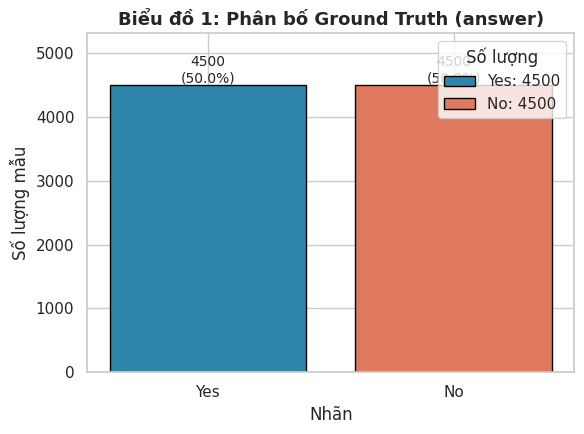

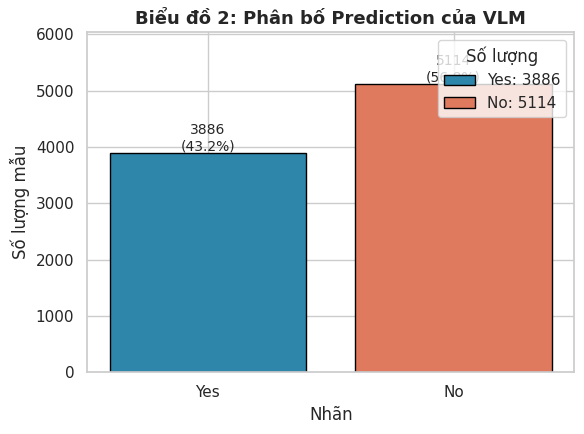

In [13]:
# 5.1 Biểu đồ 1 và 2: phân bố ground truth và prediction
LABEL_COLORS = {"Yes": "#2E86AB", "No": "#E07A5F"}


def plot_label_distribution(series, title, filename):
    # Vẽ biểu đồ cột số lượng Yes/No và lưu PNG
    counts = series.value_counts().reindex(["Yes", "No"], fill_value=0)
    total = int(counts.sum())
    fig, ax = plt.subplots(figsize=(6, 4.5))
    bars = ax.bar(counts.index, counts.values, color=[LABEL_COLORS[l] for l in counts.index], edgecolor="black")
    for bar, value in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value}\n({value / total:.1%})",
                ha="center", va="bottom", fontsize=10)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Nhãn")
    ax.set_ylabel("Số lượng mẫu")
    ax.set_ylim(0, counts.max() * 1.18 if counts.max() else 1)
    ax.legend(bars, [f"{l}: {c}" for l, c in zip(counts.index, counts.values)], title="Số lượng", loc="upper right")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_label_distribution(eval_df["answer"], "Biểu đồ 1: Phân bố Ground Truth (answer)", "ground_truth_distribution.png")
plot_label_distribution(eval_df["prediction"], "Biểu đồ 2: Phân bố Prediction của VLM", "prediction_distribution.png")

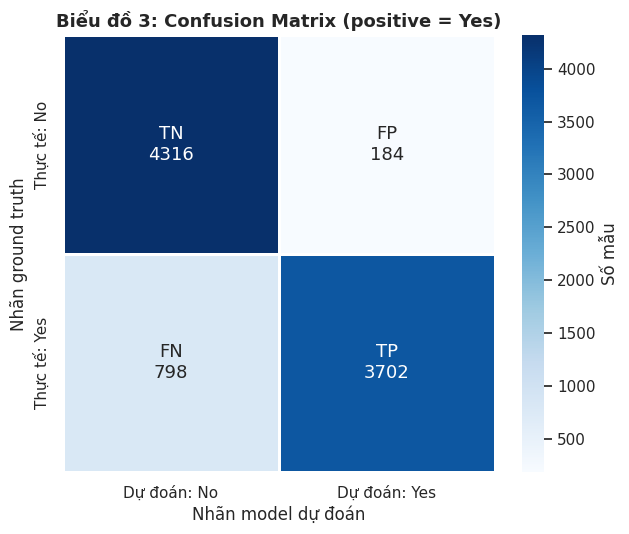

In [14]:
# 5.2 Biểu đồ 3: confusion matrix dạng heatmap
cell_names = np.array([["TN", "FP"], ["FN", "TP"]])  # Khớp thứ tự nhãn [No, Yes]
annotations = np.array([[f"{cell_names[r, c]}\n{cm_overall[r, c]}" for c in range(2)] for r in range(2)])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(cm_overall, annot=annotations, fmt="", cmap="Blues", cbar_kws={"label": "Số mẫu"},
            xticklabels=[f"Dự đoán: {l}" for l in LABELS], yticklabels=[f"Thực tế: {l}" for l in LABELS],
            linewidths=1, linecolor="white", ax=ax, annot_kws={"fontsize": 13})
ax.set_title("Biểu đồ 3: Confusion Matrix (positive = Yes)", fontsize=13, fontweight="bold")
ax.set_xlabel("Nhãn model dự đoán")
ax.set_ylabel("Nhãn ground truth")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

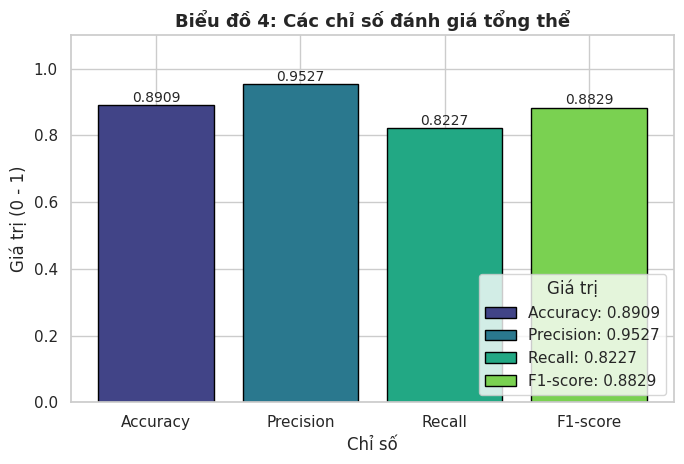

In [15]:
# 5.3 Biểu đồ 4: các chỉ số tổng thể
metric_names = ["accuracy", "precision", "recall", "f1"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1-score"]
metric_values = [overall_metrics[m] for m in metric_names]

fig, ax = plt.subplots(figsize=(7, 4.8))
bars = ax.bar(metric_labels, metric_values, color=sns.color_palette("viridis", 4), edgecolor="black")
for bar, value in zip(bars, metric_values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.4f}", ha="center", fontsize=10)
ax.set_ylim(0, 1.1)
ax.set_title("Biểu đồ 4: Các chỉ số đánh giá tổng thể", fontsize=13, fontweight="bold")
ax.set_xlabel("Chỉ số")
ax.set_ylabel("Giá trị (0 - 1)")
ax.legend(bars, [f"{l}: {v:.4f}" for l, v in zip(metric_labels, metric_values)], title="Giá trị", loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

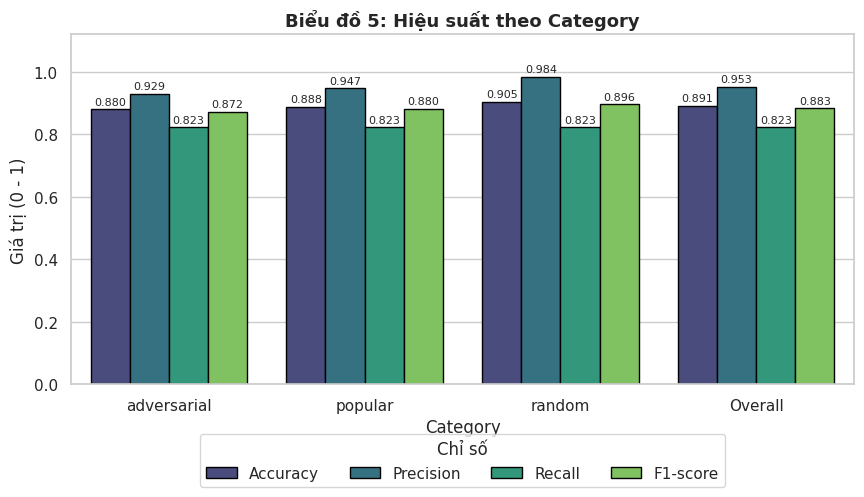

In [16]:
# 5.4 Biểu đồ 5: hiệu suất theo category
plot_df = category_metrics_df.melt(id_vars="category", value_vars=metric_names, var_name="metric", value_name="value")
plot_df["metric"] = plot_df["metric"].map(dict(zip(metric_names, metric_labels)))

fig, ax = plt.subplots(figsize=(max(8, 2.2 * len(category_metrics_df)), 5.2))
sns.barplot(data=plot_df, x="category", y="value", hue="metric", palette="viridis", edgecolor="black", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(0, 1.12)
ax.set_title("Biểu đồ 5: Hiệu suất theo Category", fontsize=13, fontweight="bold")
ax.set_xlabel("Category")
ax.set_ylabel("Giá trị (0 - 1)")
ax.legend(title="Chỉ số", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "category_performance.png", dpi=150, bbox_inches="tight")
plt.show()

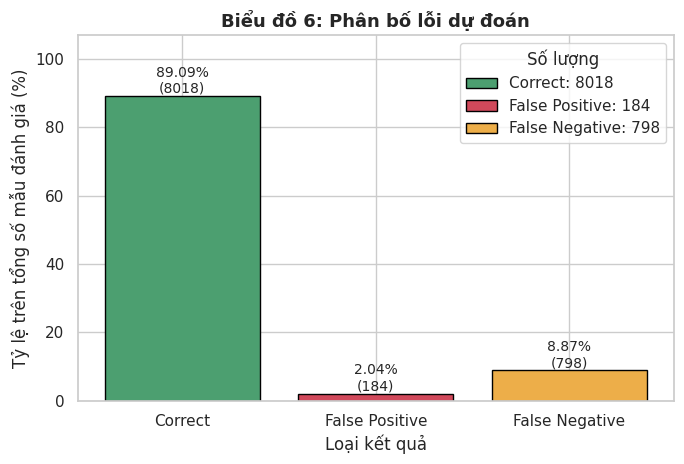

In [17]:
# 5.5 Biểu đồ 6: phân bố lỗi (Correct / False Positive / False Negative)
eval_df["outcome"] = np.select(
    [(eval_df["answer"] == "No") & (eval_df["prediction"] == "Yes"),
     (eval_df["answer"] == "Yes") & (eval_df["prediction"] == "No")],
    ["False Positive", "False Negative"], default="Correct")

outcome_order = ["Correct", "False Positive", "False Negative"]
outcome_counts = eval_df["outcome"].value_counts().reindex(outcome_order, fill_value=0)
outcome_pct = outcome_counts / outcome_counts.sum() * 100
outcome_colors = ["#4C9F70", "#D1495B", "#EDAE49"]

fig, ax = plt.subplots(figsize=(7, 4.8))
bars = ax.bar(outcome_order, outcome_pct.values, color=outcome_colors, edgecolor="black")
for bar, count, pct in zip(bars, outcome_counts.values, outcome_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, pct + 1, f"{pct:.2f}%\n({count})", ha="center", fontsize=10)
ax.set_ylim(0, max(outcome_pct.max() * 1.2, 5))
ax.set_title("Biểu đồ 6: Phân bố lỗi dự đoán", fontsize=13, fontweight="bold")
ax.set_xlabel("Loại kết quả")
ax.set_ylabel("Tỷ lệ trên tổng số mẫu đánh giá (%)")
ax.legend(bars, [f"{o}: {c}" for o, c in zip(outcome_order, outcome_counts.values)], title="Số lượng", loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

---
# PHẦN 6: PHÂN TÍCH CÁC TRƯỜNG HỢP SAI
- **False Positive**: ground truth `No`, model trả lời `Yes` → model khẳng định đối tượng không có trong ảnh (object hallucination).
- **False Negative**: ground truth `Yes`, model trả lời `No` → model bỏ sót đối tượng có trong ảnh.

Ảnh được lấy lại từ dataset gốc theo `gt_row_index`.

In [18]:
# 6.1 Tạo các DataFrame theo loại kết quả và hiển thị bảng
ANALYSIS_COLUMNS = [c for c in ["id", "question", "category", "answer", "prediction"] if c in eval_df.columns]
false_positive_df = eval_df[eval_df["outcome"] == "False Positive"].copy()
false_negative_df = eval_df[eval_df["outcome"] == "False Negative"].copy()
correct_df = eval_df[eval_df["outcome"] == "Correct"].copy()
print(f"False Positive: {len(false_positive_df)} | False Negative: {len(false_negative_df)} | Correct: {len(correct_df)}")

for title, frame in [("False Positive (GT = No, Prediction = Yes)", false_positive_df),
                     ("False Negative (GT = Yes, Prediction = No)", false_negative_df)]:
    print(f"\n=== {title} ===")
    sample_frame = frame[ANALYSIS_COLUMNS].head(NUM_ERROR_SHOW)
    try:
        display(sample_frame)
    except NameError:
        print(sample_frame.to_string())

if "category" in eval_df.columns:
    print("\nSố lỗi theo category:")
    print(pd.crosstab(eval_df["category"].fillna("(missing)"), eval_df["outcome"]))

False Positive: 184 | False Negative: 798 | Correct: 8018

=== False Positive (GT = No, Prediction = Yes) ===


,id,question,category,answer,prediction
18,1013,Is there a truck in the image?,adversarial,No,Yes
22,1017,Is there a chair in the image?,adversarial,No,Yes
46,1039,Is there a handbag in the image?,adversarial,No,Yes
68,1059,Is there a handbag in the image?,adversarial,No,Yes
79,1069,Is there a bowl in the image?,adversarial,No,Yes
102,109,Is there a bottle in the image?,adversarial,No,Yes
127,1111,Is there a car in the image?,adversarial,No,Yes
179,1159,Is there a dining table in the image?,adversarial,No,Yes



=== False Negative (GT = Yes, Prediction = No) ===


,id,question,category,answer,prediction
15,1010,Is there an orange in the imange?,adversarial,Yes,No
50,1042,Is there a traffic light in the image?,adversarial,Yes,No
56,1048,Is there a car in the image?,adversarial,Yes,No
59,1050,Is there a backpack in the image?,adversarial,Yes,No
74,1064,Is there a sports ball in the image?,adversarial,Yes,No
83,1072,Is there a bottle in the image?,adversarial,Yes,No
94,1082,Is there a sports ball in the image?,adversarial,Yes,No
115,1100,Is there a broccoli in the image?,adversarial,Yes,No



Số lỗi theo category:
outcome      Correct  False Negative  False Positive
category                                            
adversarial     2639             266              95
popular         2665             266              69
random          2714             266              20


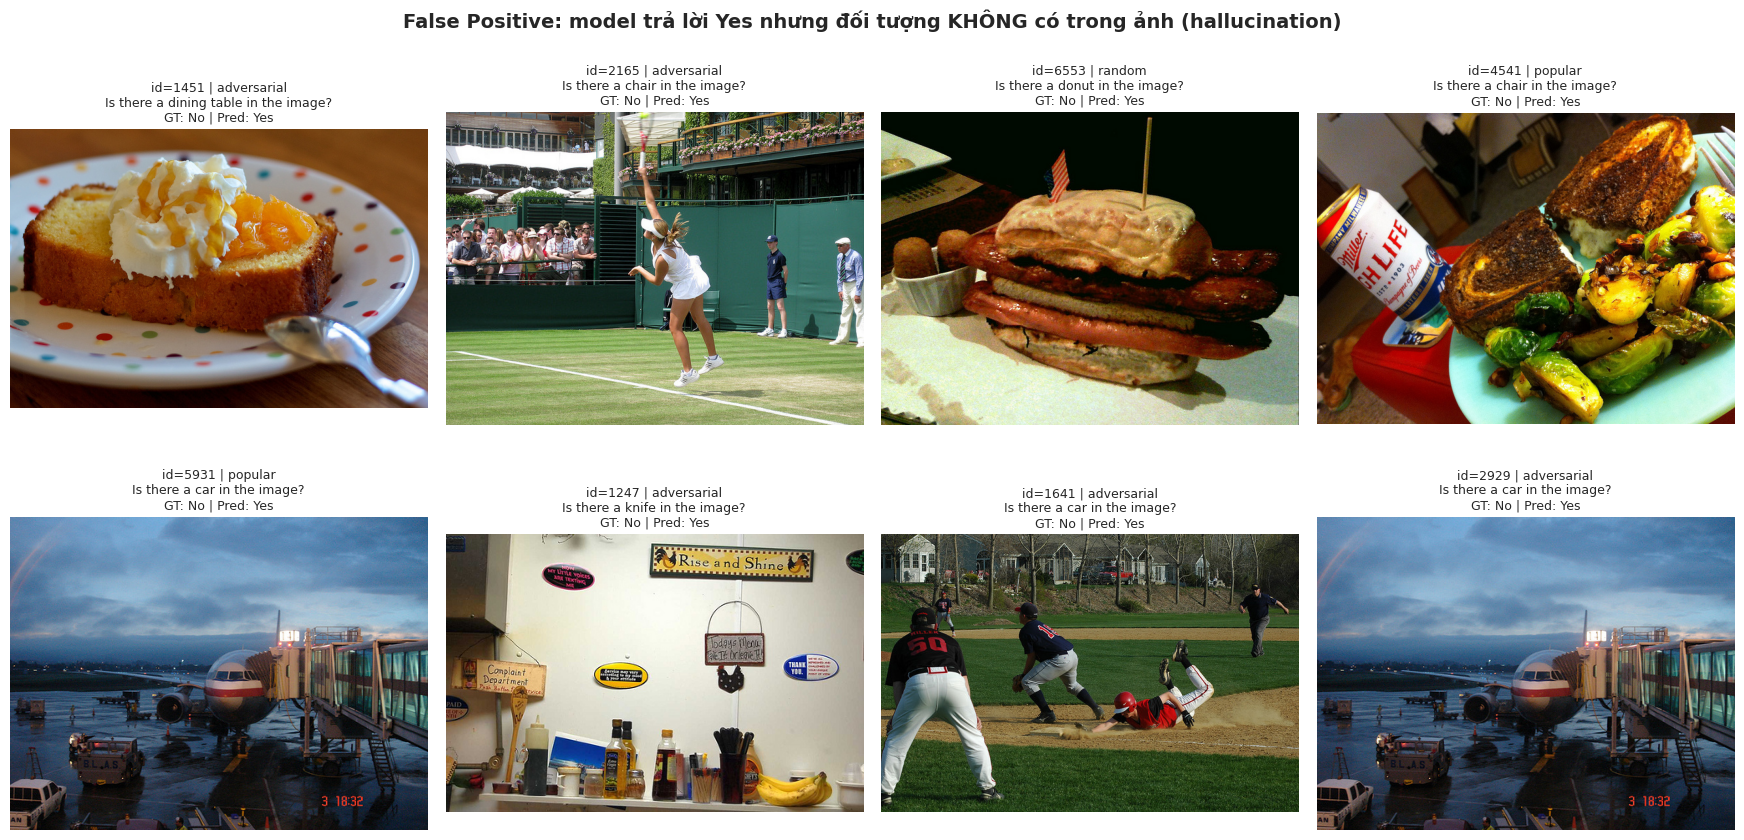

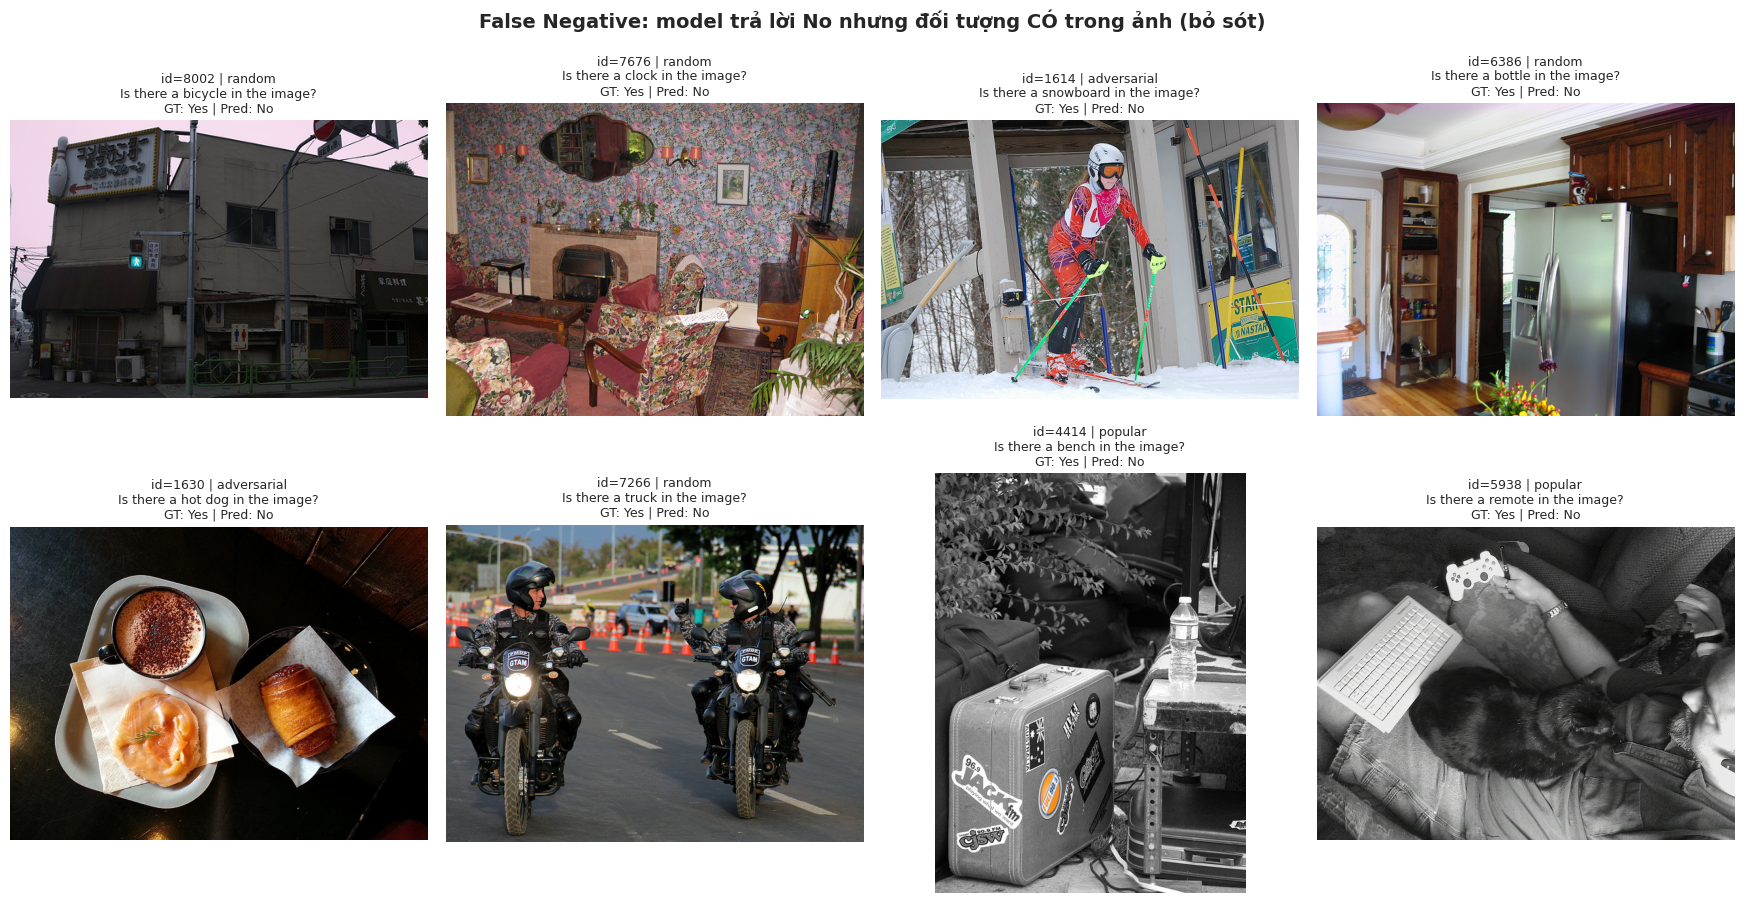

In [19]:
# 6.2 Hàm tải ảnh và hiển thị mẫu sai kèm ảnh gốc
def load_image(image_data):
    # Chuyển dữ liệu ảnh (dict bytes/path, PIL, bytes, đường dẫn) thành PIL Image RGB
    if image_data is None:
        raise ValueError("dữ liệu ảnh là None")
    if isinstance(image_data, Image.Image):
        image = image_data
    elif isinstance(image_data, dict):
        if image_data.get("bytes"):
            image = Image.open(io.BytesIO(image_data["bytes"]))
        elif image_data.get("path") and Path(image_data["path"]).is_file():
            image = Image.open(image_data["path"])
        else:
            raise ValueError("dict không có bytes và path không hợp lệ")
    elif isinstance(image_data, (bytes, bytearray)):
        image = Image.open(io.BytesIO(bytes(image_data)))
    elif isinstance(image_data, (str, Path)) and Path(image_data).is_file():
        image = Image.open(image_data)
    else:
        raise TypeError(f"kiểu ảnh không được hỗ trợ: {type(image_data).__name__}")
    image.load()
    return image.convert("RGB")


def show_cases(frame, title, n=NUM_ERROR_SHOW, cols=4):
    # Hiển thị ngẫu nhiên n mẫu của frame: ảnh + câu hỏi + GT + prediction
    if frame.empty:
        print(f"{title}: không có mẫu nào.")
        return
    chosen = frame.sample(n=min(n, len(frame)), random_state=SEED)
    rows = (len(chosen) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4.4 * cols, 4.6 * rows))
    axes = np.array(axes).reshape(-1)
    for axis in axes:
        axis.axis("off")
    for axis, (_, row) in zip(axes, chosen.iterrows()):
        try:
            axis.imshow(load_image(gt_ds[int(row["gt_row_index"])]["image"]))
        except Exception as exc:
            axis.text(0.5, 0.5, f"Không đọc được ảnh\n{exc}", ha="center", va="center", wrap=True)
        axis.set_title(f"id={row['id']} | {row.get('category', '')}\n" + textwrap.fill(str(row["question"]), 42) +
                       f"\nGT: {row['answer']} | Pred: {row['prediction']}", fontsize=9)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.tight_layout()
    plt.show()


show_cases(false_positive_df, "False Positive: model trả lời Yes nhưng đối tượng KHÔNG có trong ảnh (hallucination)")
show_cases(false_negative_df, "False Negative: model trả lời No nhưng đối tượng CÓ trong ảnh (bỏ sót)")

---
# PHẦN 7: LƯU KẾT QUẢ EVALUATION
Lưu vào `evaluation_output/`: `evaluation_results.csv`, `metrics.json`, `classification_report.json`, `category_metrics.csv`, `false_positive.csv`, `false_negative.csv` cùng 6 biểu đồ PNG đã lưu ở Phần 5.

In [20]:
# 7.1 Ghi các file kết quả
def to_builtin(value):
    # Chuyển numpy sang kiểu Python để ghi JSON
    if isinstance(value, np.generic):
        return value.item()
    return str(value)


eval_df.to_csv(OUTPUT_DIR / "evaluation_results.csv", index=False, encoding="utf-8")

metrics_payload = {
    "positive_label": POSITIVE_LABEL,
    "labels_order": LABELS,
    "accuracy": overall_metrics["accuracy"],
    "precision": overall_metrics["precision"],
    "recall": overall_metrics["recall"],
    "f1_score": overall_metrics["f1"],
    "yes_ratio": overall_metrics["yes_ratio"],
    "false_positive_rate": overall_metrics["false_positive_rate"],
    "confusion_matrix": {"TP": overall_metrics["tp"], "TN": overall_metrics["tn"],
                         "FP": overall_metrics["fp"], "FN": overall_metrics["fn"]},
    "num_evaluated_samples": overall_metrics["samples"],
    "data_coverage": {**coverage, "excluded_from_metrics": int(len(excluded_after_merge))},
    "merge_key": MERGE_KEY,
    "predictions_file": str(PREDICTIONS_PATH),
    "ground_truth_dataset": DATASET_NAME,
    "ground_truth_split": GT_SPLIT_NAME,
    "model_name": inference_summary.get("model_name"),
}
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics_payload, file, ensure_ascii=False, indent=2, default=to_builtin)
with open(OUTPUT_DIR / "classification_report.json", "w", encoding="utf-8") as file:
    json.dump(report_dict, file, ensure_ascii=False, indent=2, default=to_builtin)

category_metrics_df.to_csv(OUTPUT_DIR / "category_metrics.csv", index=False, encoding="utf-8")
false_positive_df.to_csv(OUTPUT_DIR / "false_positive.csv", index=False, encoding="utf-8")
false_negative_df.to_csv(OUTPUT_DIR / "false_negative.csv", index=False, encoding="utf-8")

expected_files = ["evaluation_results.csv", "metrics.json", "classification_report.json", "category_metrics.csv",
                  "false_positive.csv", "false_negative.csv", "ground_truth_distribution.png",
                  "prediction_distribution.png", "confusion_matrix.png", "metrics_comparison.png",
                  "category_performance.png", "error_distribution.png"]
print("Kiểm tra các file đã lưu trong", OUTPUT_DIR.resolve())
for file_name in expected_files:
    file_path = OUTPUT_DIR / file_name
    status_text = f"{file_path.stat().st_size / 1024:.1f} KB" if file_path.exists() else "THIẾU"
    print(f" - {file_name:<32} {status_text}")

Kiểm tra các file đã lưu trong /kaggle/working/evaluation_output
 - evaluation_results.csv           856.9 KB
 - metrics.json                     0.8 KB
 - classification_report.json       0.6 KB
 - category_metrics.csv             0.6 KB
 - false_positive.csv               18.8 KB
 - false_negative.csv               81.3 KB
 - ground_truth_distribution.png    44.2 KB
 - prediction_distribution.png      45.6 KB
 - confusion_matrix.png             59.7 KB
 - metrics_comparison.png           63.5 KB
 - category_performance.png         56.7 KB
 - error_distribution.png           69.3 KB


In [21]:
# 7.2 Bảng tổng hợp kết quả đánh giá
summary_table = pd.DataFrame([
    ("Mô hình", inference_summary.get("model_name", "(không rõ)")),
    ("Dataset / split", f"{DATASET_NAME} / {GT_SPLIT_NAME}"),
    ("Khoá ghép", ", ".join(MERGE_KEY)),
    ("Số dòng prediction", coverage["prediction_rows"]),
    ("Số mẫu ghép được", coverage["matched"]),
    ("Số mẫu bị loại khỏi metrics (error/Invalid/GT lạ)", len(excluded_after_merge)),
    ("Số mẫu được đánh giá", overall_metrics["samples"]),
    ("Accuracy", round(overall_metrics["accuracy"], 4)),
    ("Precision (positive = Yes)", round(overall_metrics["precision"], 4)),
    ("Recall (positive = Yes)", round(overall_metrics["recall"], 4)),
    ("F1-score (positive = Yes)", round(overall_metrics["f1"], 4)),
    ("Yes-ratio", round(overall_metrics["yes_ratio"], 4)),
    ("False Positive Rate", round(overall_metrics["false_positive_rate"], 4)),
    ("TP / TN / FP / FN", f"{overall_metrics['tp']} / {overall_metrics['tn']} / {overall_metrics['fp']} / {overall_metrics['fn']}"),
], columns=["Hạng mục", "Giá trị"])
try:
    display(summary_table)
except NameError:
    print(summary_table.to_string(index=False))

print("\nHiệu suất theo category:")
try:
    display(category_metrics_df[["category", "samples", "accuracy", "precision", "recall", "f1", "yes_ratio"]].round(4))
except NameError:
    print(category_metrics_df[["category", "samples", "accuracy", "precision", "recall", "f1", "yes_ratio"]].round(4).to_string())

,Hạng mục,Giá trị
0,Mô hình,Qwen/Qwen3-VL-4B-Instruct
1,Dataset / split,lmms-lab-encoder/POPE / test
2,Khoá ghép,id
3,Số dòng prediction,9000
4,Số mẫu ghép được,9000
5,Số mẫu bị loại khỏi metrics (error/Invalid/GT lạ),0
6,Số mẫu được đánh giá,9000
7,Accuracy,0.8909
8,Precision (positive = Yes),0.9527
9,Recall (positive = Yes),0.8227



Hiệu suất theo category:


,category,samples,accuracy,precision,recall,f1,yes_ratio
0,adversarial,3000,0.8797,0.9285,0.8227,0.8724,0.4430
1,popular,3000,0.8883,0.9470,0.8227,0.8805,0.4343
2,random,3000,0.9047,0.9841,0.8227,0.8962,0.4180
3,Overall,9000,0.8909,0.9527,0.8227,0.8829,0.4318
